Este código foi criado para desenvolver um modelo de CNN para quantificar células marcadas com fluorescencia, indicando presença da proteína na célula.

# Imports data structuring

In [1]:
#organização dos arquivos
import os
#salvar/carregar arquivos em diferentes formatos
import joblib
#organizando os arquivos de forma aleatória
import random
#gerar gráfico
import matplotlib
#estruturação dos dados
import numpy as np
#gerar gráfico
import seaborn as sns
#gerar gráfico
import matplotlib.pyplot as plt
#gerar imagem
import matplotlib.image as mpimg

# CNN template import

In [2]:
#modelo de revisão redes neurais - cnn
from keras.models import Sequential
from keras.utils import to_categorical # Import directly from keras.utils
from util import meus_uteis, timeProcess, mask_corr_graphic, printLis
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
from keras.layers import Dense, Conv2D, MaxPooling2D, Dropout, Flatten

2026-10-17 11:35:26.207447: I tensorflow/core/util/port.cc:110] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-17 11:35:26.245504: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-17 11:35:26.432751: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-17 11:35:26.436973: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
/usr/local/lib/python3.10/site-packages/google/api_core/_python_version_support.py:246: FutureWarning: You are us

Documents from different files will be stored in this directory

In [8]:
diretorio = "./data/imagens de fluorescencia/"
lista_dados = [i for i in os.listdir(link) if i.endswith('.gz')]
printLis(lista_dados) #printando as diferentes listas

-------------
-=< Lista >=-
-------------
0 -> lista_img_100_resized_fluorescente_cho745_2026-10-17.gz
1 -> lista_img_25_resized_fluorescente_cho745_2026-10-17.gz
2 -> lista_img_50_resized_fluorescente_cho745_2026-10-17.gz
3 -> lista_img_75_resized_fluorescente_cho745_2026-10-17.gz
4 -> lista_rotulo_100_resized_fluorescente_cho745_2026-10-17.gz
5 -> lista_rotulo_25_resized_fluorescente_cho745_2026-10-17.gz
6 -> lista_rotulo_50_resized_fluorescente_cho745_2026-10-17.gz
7 -> lista_rotulo_75_resized_fluorescente_cho745_2026-10-17.gz


Lists of all images in each file

## x = features/images

In [9]:
#0 - 100% somando todas as imagens de diferentes tamanho
X_cem = joblib.load(diretorio+ '/' + lista_dados[0])

# 3 - 75%
X_setcin = joblib.load(diretorio+ '/' + lista_dados[3])

# 2 - 50%
X_cinq = joblib.load(diretorio+ '/' + lista_dados[2])

# 1 - 25%
X_vincin = joblib.load(diretorio+ '/' + lista_dados[1])

x = np.asarray(list(X_cem) + list(X_setcin) + list(X_cinq) + list(X_vincin))

x.shape

(640, 250, 300, 3)

# y = labels

Opening the labels that were saved in the preparation of the images

In [10]:
#4 - 100% somando todos os rótulos de diferentes tamanho
y_cem = joblib.load(diretorio+ '/' + lista_dados[4])

#7 - 75%
y_setcin = joblib.load(diretorio+ '/' + lista_dados[7])

#6 - 50%
y_cinq = joblib.load(diretorio+ '/' + lista_dados[6])

#5 - 25%
y_vincin = joblib.load(diretorio+ '/' + lista_dados[5])

y = np.asarray(list(y_cem) + list(y_setcin) + list(y_cinq) + list(y_vincin))

y.shape

(640,)

#Separando dados de validação

In [11]:
#Train and test split datasets for CNN model
#função que separa as imagens em teste e treino
from sklearn.model_selection import train_test_split

10% dos 640 - foram separados para validação do modelo.

In [12]:
zeros = list(np.zeros(576))
ones = list(np.ones(64))
lista = np.array(zeros + ones)
#lista

In [13]:
random.shuffle(lista)
lista_valida = [True if i == 1 else False for i in lista]
lista_treino_test = [False if i == 1 else True for i in lista]
#np.array(lista_valida)

In [14]:
#imagens
x_valida = x[lista_valida]
x_treino_test = x[lista_treino_test]

print(x_valida.shape)
print(x_treino_test.shape)

(64, 250, 300, 3)
(576, 250, 300, 3)


In [15]:
#rótulos
y_valida = y[lista_valida]
y_treino_test = y[lista_treino_test]

print(y_valida.shape)
print(y_treino_test.shape)

(64,)
(576,)


In [16]:
data = timeProcess()[1]
#Salvando 10$ das imagens para validação
joblib.dump(x_valida, f'{diretorio}imagens_validação_10%_fluore_'+data+'.gz')
joblib.dump(y_valida, f'{diretorio}rótulos_validação_10%_fluore_'+data+'.gz')

['./data/imagens de fluorescencia/rótulos_validação_10%_fluore_2026-10-17.gz']

Test and training separation from a library.

In [17]:
X_train, X_test, y_train, y_test = train_test_split(x_treino_test, y_treino_test, test_size=0.3, random_state=0)
#variáveis recebem o número de imagens para tes e treino
print(f'{X_train.shape} \n{X_test.shape} \n{y_train.shape} \n{y_test.shape}')

(403, 250, 300, 3) 
(173, 250, 300, 3) 
(403,) 
(173,)


In [18]:
y_train = y_train.astype(int)
y_test = y_test.astype(int)
# print(int_array)
# print(int_array.dtype)


### Model determination

In [19]:
modelo = Sequential()
modelo.add(Conv2D(32, kernel_size=3, activation='relu', input_shape=X_train[0].shape))
#função de ativação relu é muito utilizado para problemas de regressão
modelo.add(MaxPooling2D(pool_size=(2, 2), strides=(2, 2), padding='valid'))
modelo.add(Conv2D(64, kernel_size=3, activation='relu'))
modelo.add(MaxPooling2D(pool_size=(2, 2), strides=(2, 2), padding='valid'))
modelo.add(Conv2D(128, kernel_size=3, activation='relu'))
modelo.add(MaxPooling2D(pool_size=(2, 2), strides=(2, 2), padding='valid'))
modelo.add(Conv2D(256, kernel_size=3, activation='relu'))
modelo.add(MaxPooling2D(pool_size=(2, 2), strides=(2, 2), padding='valid'))
modelo.add(Flatten())
modelo.add(Dropout(0.2))
modelo.add(Dense(1, activation='linear'))
#apenas uma saída e de forma linear
modelo.compile(optimizer='adam', loss='mse', metrics=['mean_squared_error'])
print(modelo.summary())

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 248, 298, 32)      896       
                                                                 
 max_pooling2d (MaxPooling2D  (None, 124, 149, 32)     0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 122, 147, 64)      18496     
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 61, 73, 64)       0         
 2D)                                                             
                                                                 
 conv2d_2 (Conv2D)           (None, 59, 71, 128)       73856     
                                                                 
 max_pooling2d_2 (MaxPooling  (None, 29, 35, 128)      0

# Training and testing epochs

In [20]:
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.callbacks import ModelCheckpoint

In [21]:
# simple early stopping
es = EarlyStopping(monitor='val_loss', mode='min', verbose=1, patience=18)

In [22]:
# fit model
history = modelo.fit(X_train,y_train,
                    validation_data=(X_test, y_test),
                    epochs=200, verbose=2,
                    callbacks=[es]
                     )

Epoch 1/200
13/13 - 37s - loss: 5141.0967 - mean_squared_error: 5141.0967 - val_loss: 1118.4946 - val_mean_squared_error: 1118.4946 - 37s/epoch - 3s/step
Epoch 2/200
13/13 - 29s - loss: 1163.6115 - mean_squared_error: 1163.6115 - val_loss: 996.5441 - val_mean_squared_error: 996.5441 - 29s/epoch - 2s/step
Epoch 3/200
13/13 - 27s - loss: 1095.6942 - mean_squared_error: 1095.6942 - val_loss: 1143.7499 - val_mean_squared_error: 1143.7499 - 27s/epoch - 2s/step
Epoch 4/200
13/13 - 20s - loss: 776.4856 - mean_squared_error: 776.4856 - val_loss: 1079.5739 - val_mean_squared_error: 1079.5739 - 20s/epoch - 2s/step
Epoch 5/200
13/13 - 19s - loss: 681.2225 - mean_squared_error: 681.2225 - val_loss: 838.5341 - val_mean_squared_error: 838.5341 - 19s/epoch - 1s/step
Epoch 6/200
13/13 - 18s - loss: 584.4142 - mean_squared_error: 584.4142 - val_loss: 700.5424 - val_mean_squared_error: 700.5424 - 18s/epoch - 1s/step
Epoch 7/200
13/13 - 16s - loss: 502.8277 - mean_squared_error: 502.8277 - val_loss: 709.

## Accuracy Assessment

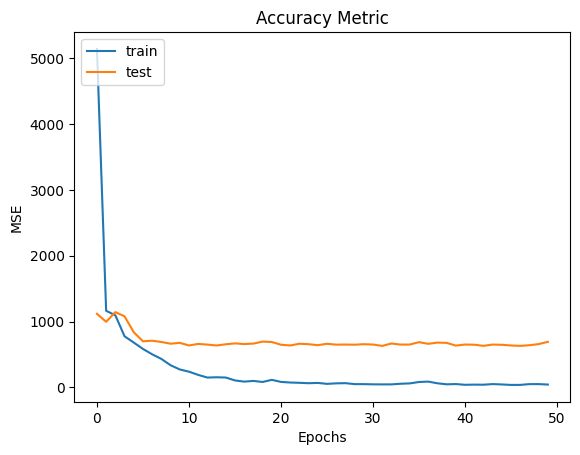

In [23]:
#gráfico avaliando a acurácia a partir de treino e teste
plt.plot(history.history['mean_squared_error'])
plt.plot(history.history['val_mean_squared_error'])
plt.title('Accuracy Metric')
plt.ylabel('MSE')
plt.xlabel('Epochs')
plt.legend(['train', 'test'], loc='upper left')
plt.show()

6/6 [==============================] - 1s 191ms/step


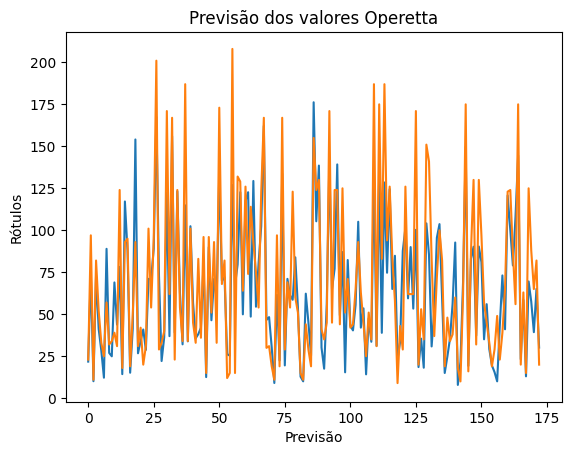

In [24]:
#avaliando a previsão do modelo com os rótulos
prev = modelo.predict(X_test)
plt.title('Previsão dos valores Operetta')
plt.ylabel('Rótulos')
plt.xlabel('Previsão')
plt.plot(prev)#azul - o que o modelo previu
plt.plot(y_test)#laranja - o que se sabe - observado
plt.show()

In [25]:
# Qualit model analisys
from sklearn.metrics import r2_score,mean_absolute_error, mean_squared_error, mean_squared_log_error, median_absolute_error

In [ ]:
#buscando pelas métricas
print(f"{round(r2_score(y_test, prev) * 100, 2)}% r2_score") #raíz quadrada
print(f"{round(mean_absolute_error(y_test, prev), 2)} Erro médio absoluto")
print(f"{round(mean_squared_error(y_test, prev), 2)} Erro médio quadrático") #erro médio quadrático
# print(f"{round(median_absolute_error(y_test, prev), 2)}")#Erro médio absoluto sem %
#print(f"{round(median(y_test, prev), 2)} mediana") #erro médio quadrático

86.48% r2_score
13.26 Erro médio absoluto
302.32 Erro médio quadrático


In [27]:
modelo.save(f'{diretorio}modelo_fluore_100_75_50_25_'+data+'.keras')